# T09: Handling Large-Scale Neuronal Data

## Overview

This tutorial shows how to work with volumes that do not fit in memory: inspecting a remote OME-Zarr pyramid without downloading it, pulling small regions into RAM, tracing them automatically, and sharing the result as a link that reopens in *SNT Stream* (SNT's out-of-core, BDV/BVV-based tracing mode).

```{admonition} Learning Objectives
:class: tip

By the end of this tutorial, you will be able to:
1. Inspect a remote OME-Zarr dataset (levels, calibration, chunking) without reading its pixels
2. Open a pyramid level lazily and materialize the extent of a reconstructed neuron
3. Trace a materialized region automatically (GWDT)
4. Render the region and its reconstruction in BigVolumeViewer (BVV, GPU) or BigDataViewer (BDV, no GPU needed), and capture screenshots
5. Create `fiji://snt/` links that reopen the data in SNT Stream

**Estimated Time**: 30 minutes
```

```{note}
Make sure to read these resources before running this notebook:
- [Install](../install.md) - Installation instructions
- [Limitations](../limitations.md) - Java GUIs on macOS
- [Tutorial 07](./07_curvature_optimization.ipynb) - A* tracing optimization
```

```{warning}
**Extra Requirements:** An internet connection (the dataset is streamed from S3). The viewer section requires a display: BVV also requires a GPU. Set `VIEWER = 'bdv'` below on older hardware, or `VIEWER = None` to skip it.
```

## Introduction

[OME-Zarr](https://ngff.openmicroscopy.org/) (OME-NGFF) stores images as compressed chunks arranged in a multi-resolution pyramid, so a viewer only fetches the chunks it needs at the resolution it needs. SNT reads OME-Zarr (and N5) natively, from local folders, HTTP(S) and S3: no Python zarr package is required, and everything below runs in the same Java code that powers the *Big Data... SNT Stream* command.

We will use the marmoset neuron dataset behind the *Load Remote Demo* button of that command (OME-Zarr v0.5, hosted on S3), together with a CSV of soma detections and an automated tracing of the same volume. It includes pyramidal neurons in the marmoset primary visual cortex (V1) imaged on a 2-photon microscope after retrograde labeling from area V2 (see [Data Sources and References](#data-sources-and-references) for details).

## Setup and Initialization

Java GUIs (BVV, BDV) require `interactive` mode (with some [limitations](../limitations.md) on macOS).

In [1]:
import sys
import tempfile
from pathlib import Path
from urllib.parse import quote

import pandas as pd
import pysnt

pysnt.set_option('java.logging.level', 'Error')
pysnt.set_option('display.chart_format', 'svg')
pysnt.set_option('display.chart_dpi', 150)

# Viewer for the visualization section:
#   'bvv': BigVolumeViewer, 3D rendering (needs a GPU)
#   'bdv': BigDataViewer, 2D reslicing (CPU only: older hardware, slow connections)
#   None: no viewer (headless machines)
VIEWER = 'bvv'

pysnt.initialize(mode='interactive' if VIEWER else 'headless')

In [2]:
ZARR_URL = 'https://ome-zarr-scivis.s3.us-east-1.amazonaws.com/v0.5/96x2/marmoset_neurons.ome.zarr'
DEMO_ROOT = 'https://raw.githubusercontent.com/morphonets/misc/3ffb1bee97666634faf12c060650a6052a30fc26/dataset-demos/marmoset_neurons/'
SOMAS_CSV = DEMO_ROOT + 'soma_detections.csv'
TRACINGS = DEMO_ROOT + 'autotracings.traces'

## Inspecting a Remote Dataset

`BigDataUtils.describe()` reads only the container metadata: number of channels and timepoints, chunk shape, and the dimensions, voxel size and origin of every pyramid level. Nothing is downloaded besides a few small JSON files.

In [3]:
from pysnt.util import BigDataUtils

info = BigDataUtils.describe(ZARR_URL)
print(info)

Compression 'org.janelia.saalfeldlab.n5.blosc.BloscCompression' could not be registered


marmoset_neurons.ome.zarr: 1 channel(s), 1 timepoint(s), remote, chunks [96, 96, 96]
  level 0: [1024, 1024, 314] voxels, spacing [0.497, 0.497, 1.5] , origin [-254.464, -254.464, -235.5]
  level 1: [512, 512, 314] voxels, spacing [0.994, 0.994, 1.5] , origin [-254.2155, -254.2155, -235.5]
  level 2: [256, 256, 157] voxels, spacing [1.988, 1.988, 3.0] , origin [-253.71849999999998, -253.71849999999998, -234.75]
  level 3: [128, 128, 157] voxels, spacing [3.976, 3.976, 3.0] , origin [-252.72449999999998, -252.72449999999998, -234.75]


Each level is a coarser version of the previous one (here, Z is downsampled less often than XY, hence the anisotropic voxel sizes). Note how the voxel size grows accordingly: SNT keeps the calibration consistent across levels, so locations given in calibrated (world) units map to the right voxels at any level.

In [4]:
levels = pd.DataFrame({
    'level': [l.level() for l in info.levels()],
    'dims (x,y,z)': [tuple(int(d) for d in l.dims()) for l in info.levels()],
    'voxel size': [tuple(round(float(s), 3) for s in l.spacing()) for l in info.levels()],
    'Mvoxels': [round(float(l.dims()[0] * l.dims()[1] * l.dims()[2]) / 1e6, 1) for l in info.levels()],
})
levels

,level,"dims (x,y,z)",voxel size,Mvoxels
0,0,"(1024, 1024, 314)","(0.497, 0.497, 1.5)",329.3
1,1,"(512, 512, 314)","(0.994, 0.994, 1.5)",82.3
2,2,"(256, 256, 157)","(1.988, 1.988, 3.0)",10.3
3,3,"(128, 128, 157)","(3.976, 3.976, 3.0)",2.6


## Opening a Level Lazily

`openChannel()` returns a lazy image: pixels are only fetched when something reads them. We open a coarse *overview* level of the first channel, small enough to browse quickly. Other levels can be opened the same way, and will be touched only through crops.

In [5]:
# Finest level below ~200 Mvoxels
overview_level = next((int(l.level()) for l in info.levels()
                       if l.dims()[0] * l.dims()[1] * l.dims()[2] <= 2e8), int(info.nLevels()) - 1)

overview = BigDataUtils.openChannel(ZARR_URL, 0, 0, overview_level).toImgPlus()
dims = [int(overview.dimension(d)) for d in range(3)]
print(f"Level {overview_level}: {dims}, voxel size {overview.averageScale(0):.3f} {overview.axis(0).unit() or 'units'}")

Level 1: [512, 512, 314], voxel size 0.994 units


## A Montage of Soma Detections

The `soma_detections.csv` file lists soma locations in calibrated (world) coordinates. `NodeCollector` crops a window around each location, and can assemble the crops into a montage. Working on the overview level, only the few chunks around each soma are fetched.

In [6]:
from pysnt.analysis import NodeCollector
from pysnt.util import SNTPoint

somas = pd.read_csv(SOMAS_CSV)
print(f"{len(somas)} detections")
somas.head()

26 detections


,Tag,Label,X,Y,Z,C,T,Size
0,#D70000,detected_soma001,-134.342807,-38.685269,-96.255399,-,1,5.0
1,#8C3CFF,detected_soma002,92.843847,-198.114500,-98.646837,-,1,5.0
2,#028800,detected_soma003,52.986540,-159.253625,-104.426147,-,1,5.0
3,#00ACC7,detected_soma004,-67.581817,-11.781586,-108.112948,-,1,5.0
4,#98FF00,detected_soma005,-52.635326,-175.196548,-75.828528,-,1,5.0


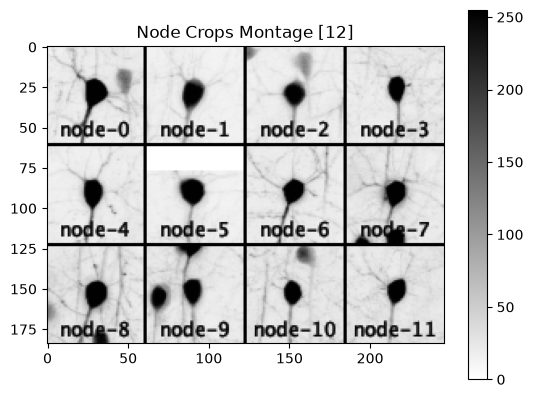

In [7]:
# Window sizes in calibrated units, converted to voxels of the overview level
WIN_XY, WIN_Z = 60, 40
sxy, sz = overview.averageScale(0), overview.averageScale(2)

points = [SNTPoint.of(float(r.X), float(r.Y), float(r.Z)) for r in somas.head(12).itertuples()]
collector = (NodeCollector(overview, points)
             .setPointsInPixelSpace(False)
             .setWindow(max(8, round(WIN_XY / sxy)), max(2, round(WIN_Z / sz)))
             .setProjection(NodeCollector.Projection.MIP_Z))

montage = collector.getMontage(-1, -1, 1, 2, True)  # cols, rows (auto), scale, border, labels
_ = pysnt.display(montage)

## Materializing the Extent of a Neuron

Streamed data is lazy by design, so operations that need random access to many voxels (filtering, measuring) would hammer the network. The remedy is to *materialize* the region you need: copy it into RAM once and work on that copy.

Rather than a fixed window, we crop the region spanned by a reconstruction. This is the logic of the *Auto-bounds* options of SNT's *Materialize Region* dialog (SNT Stream): take the bounding box of the paths, pad it, and read it. Here we load the automated tracings, pick the cell closest to the first soma detection, and read its padded bounding box at the finest pyramid level that fits a voxel budget.

In [8]:
from pysnt import Tree
from pysnt.util import ImgUtils

soma = points[0]
trees = list(Tree.listFromFile(TRACINGS))

def root_distance(t):
    r = t.getRoot()
    if r is None:
        return float('inf')
    return ((r.getX() - soma.getX())**2 + (r.getY() - soma.getY())**2 + (r.getZ() - soma.getZ())**2) ** 0.5

neuron = min(trees, key=root_distance)
neuron.setLabel('Provided')
print(f"{len(trees)} trees. Closest root is {root_distance(neuron):.1f} units from the soma")

PAD = 10            # calibrated units added around the bounding box
MAX_VOXELS = 5e7    # budget for the materialized region

box = neuron.getBoundingBox()
extent = [box.width() + 2 * PAD, box.height() + 2 * PAD, box.depth() + 2 * PAD]

def voxels(level):
    n = 1
    for e, s in zip(extent, level.spacing()):
        n *= e / s
    return n

crop_level = next((int(l.level()) for l in info.levels() if voxels(l) <= MAX_VOXELS), int(info.nLevels()) - 1)
print(f"Level {crop_level}: ~{voxels(info.levels()[crop_level]) / 1e6:.0f} Mvoxels")

source = BigDataUtils.openChannel(ZARR_URL, 0, 0, crop_level).toImgPlus()
crop = ImgUtils.crop(source, box, float(PAD), True)  # True: materialize in RAM
print(f"Crop: {[int(crop.dimension(d)) for d in range(3)]} voxels in RAM")

17 trees. Closest root is 2.1 units from the soma
Level 0: ~3 Mvoxels
Crop: [146, 351, 69] voxels in RAM


## Automated Tracing of the Materialized Region

SNT's GWDT tracer (Gray-Weighted Distance Transform) reconstructs the neurites of an image without user input. The factory picks the storage backend (in-memory array, sparse, or disk-backed) that fits the available memory, which is what allows the same call to scale from this crop to much larger regions. We compare the result with the provided tracing of the same cell.

Backend: GWDTTracer
Provided: 437 nodes, cable length: 469.9 units
GWDT: 507 nodes, cable length: 740.5 units
[SNTUtils] Retrieving org.scijava.Context...
[INFO] [SNTUtils] 102 scijava services loaded


{'type': matplotlib.figure.Figure,
 'data': <Figure size 700x350 with 2 Axes>,
 'metadata': {'source_type': 'SNTChart_List',
  'sntchart_count': 2,
  'displayed_count': 2,
  'panel_layout': 'auto',
  'title': None},
 'error': None}

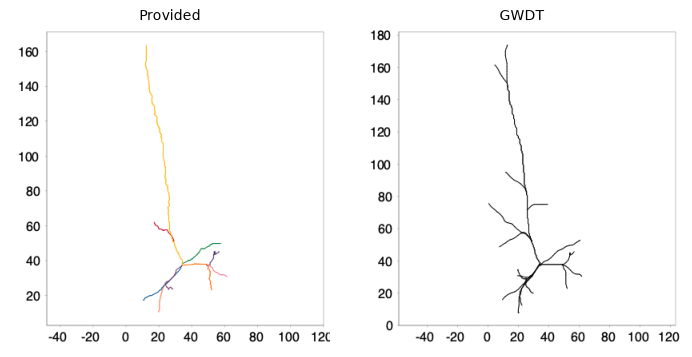

In [9]:
from pysnt.tracing.auto import GWDTTracerFactory
from pysnt.analysis import TreeStatistics

# The crop is traced (and displayed by the viewers) in its own, zero-based frame:
# bring the provided tracing into it
ox, oy, oz = ImgUtils.getOrigins(crop)

tracer = GWDTTracerFactory.create(crop)
print(f"Backend: {tracer.getClass().getSimpleName()}")

# Parameters of SNT's automated tracing (same as in the GUI's GWDT dialog)
tracer.setBackgroundThreshold(55)           # pixels <= 55 are background
tracer.setScoreMapEnabled(True)             # prune low-confidence branches with a Tubeness score map...
tracer.setMinBranchIntensityLength(5)       # ... discarding branches scoring below this value
tracer.setSrRatio(0.3)                      # branch sensitivity
tracer.setSphereOverlapThreshold(0.1)       # overlap tolerance
tracer.setLeafPruneOverlap(0.9)             # strict tip filtering
tracer.setTipExtensionDistance(4)           # bridge gaps of up to 4 voxels at tips

# The tracer needs a seed: the root of the provided tracing (the soma), in the crop's own frame
root = neuron.getRoot()
tracer.setSeedPhysical([root.getX() - ox, root.getY() - oy, root.getZ() - oz])

tree = tracer.trace()
tree.setLabel('GWDT')

neuron_local = neuron.clone()
neuron_local.translate(-ox, -oy, -oz)

unit = crop.axis(0).unit() or 'units'  # the dataset does not specify one
for t in (neuron_local, tree):
    print(f"{t.getLabel()}: {t.getNodesCount()} nodes, cable length: {TreeStatistics(t).getCableLength():.1f} {unit}")
pysnt.display([neuron_local, tree])

## Visualization in a Big Viewer

We render the materialized crop with both reconstructions. Because the crop is in RAM, this is fast and safe, whatever the size of the parent dataset. Both viewers share the same API, so the code below works with either:

- **BigVolumeViewer (BVV)**: GPU-accelerated 3D rendering. It is the viewer of choice when a GPU is available.
- **BigDataViewer (BDV)**: renders a single, resliceable plane on the CPU. It is the fallback for machines without a (decent) GPU, and it copes better with slow connections because it only fetches the pixels of the plane in view.

```{note}
On macOS, Java GUI calls must be queued on the Java event dispatch thread, otherwise the cell may hang: `pysnt.run_on_edt()` takes care of this (see [Limitations](../limitations.md)). Queued code runs after the cell finishes, which is why the screenshot is taken in a separate cell. Set `VIEWER = None` to skip this section.
```

In [20]:
from pysnt.viewer import Bvv, Bdv

viewer = None

def show_viewer():
    global viewer
    viewer = {'bvv': Bvv, 'bdv': Bdv}[VIEWER]()
    neuron_local.setColor('cyan')   # provided tracing
    tree.setColor('magenta')        # GWDT tracing
    viewer.add(neuron_local)
    viewer.add(tree)
    viewer.show(crop)
    if VIEWER == 'bdv':
        # BDV shows a single plane: move it to where the reconstruction is
        root = tree.getRoot()
        viewer.flyTo(root.getX(), root.getY(), root.getZ(), -1, None)

if VIEWER:
    pysnt.run_on_edt(show_viewer)
else:
    print("Skipped (VIEWER is None)")

Once the viewer is up, `snapshot()` returns the current scene as an image. It must be called from a regular (non-EDT) thread, which is the case for a notebook cell, and it waits for the renderer to deliver a fresh frame. Saving screenshots this way embeds them in the notebook, so they remain visible to readers without a GPU.

```{note}
The window is created while the kernel is idle, i.e., after the viewer cell has finished, so the snapshot cell can only succeed once the window is visible. When using *Run All*, the snapshot cell may thus run too early: simply run it again once the viewer is on screen. Conversely, keep the viewer window open until the snapshot has been taken: once it is closed, its scene can no longer be captured.
```

BVV-current: 1284 x 2048 pixels


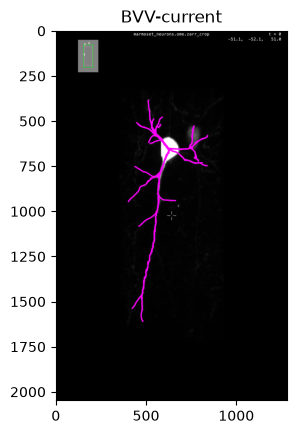

In [21]:
import time

if VIEWER and viewer is not None:
    # The window opens on the EDT after the viewer cell returns: poll until the scene is ready
    screenshot = None
    for _ in range(30):
        screenshot = viewer.snapshot()
        if screenshot is not None:
            break
        time.sleep(1)
    if screenshot is None:
        print("No snapshot: the viewer did not initialize in 30s. Check that its window is open and rerun this cell")
    else:
        print(f"{screenshot.getTitle()}: {screenshot.getWidth()} x {screenshot.getHeight()} pixels")
        _ = pysnt.display(screenshot)
else:
    print("No viewer to capture (VIEWER is None, or the viewer cell has not run yet)")

### Streaming the Whole Volume in BDV

BDV can also open the *whole* remote dataset: it reslices the pyramid on the fly, fetching only the chunks of the plane in view at the resolution the zoom level requires. No full-volume texture is ever uploaded, which makes it the lightest way to browse the dataset on older hardware or a slow connection (for BVV, see the slab section below).

Close the viewer opened above first (only one viewer is kept per session), then navigate with the mouse: scroll to change plane and drag to pan.

In [22]:
from pysnt.util import BigDataUtils

stream_viewer = None

def stream_whole_volume():
    global stream_viewer
    stream_viewer = Bdv()
    # N5Sources: lazy, multi-resolution sources of every channel of the container
    stream_viewer.show(BigDataUtils.resolvePathToSource(ZARR_URL))

if VIEWER == 'bdv':
    pysnt.run_on_edt(stream_whole_volume)
else:
    print("Skipped (set VIEWER = 'bdv' to run this cell)")

Skipped (set VIEWER = 'bdv' to run this cell)


In [23]:
if VIEWER == 'bdv' and stream_viewer is not None:
    time.sleep(5)  # remote chunks take a while to arrive
    _ = pysnt.display(stream_viewer.snapshot())

### Streaming the Whole Volume in BVV with a Slab

BVV can stream the whole dataset too (tile by tile, at the resolution the zoom level requires), but a 3D view requests many blocks from every depth. *Slab mode* restricts rendering, and thus loading, to a slab of the volume: only blocks intersecting it are fetched, which keeps remote browsing responsive. Slab mode is a BVV feature (BDV only ever reads the plane in view) and is also available from the *Slab View* controls of the BVV toolbar.

Close the viewers opened above first, set `VIEWER = 'bvv'` in the setup cell and `STREAM_BVV = True` in the first cell below. The slab is centered on the first soma and is 20 calibrated units thick.

In [ ]:
STREAM_BVV = False  # set to True to stream the whole volume in a (second) BVV window

stream_bvv = None

def stream_whole_volume_bvv():
    global stream_bvv
    stream_bvv = Bvv()
    stream_bvv.show(BigDataUtils.resolvePathToSource(ZARR_URL))

if VIEWER == 'bvv' and STREAM_BVV:
    pysnt.run_on_edt(stream_whole_volume_bvv)
else:
    print("Skipped (set VIEWER = 'bvv' and STREAM_BVV = True to run this cell)")

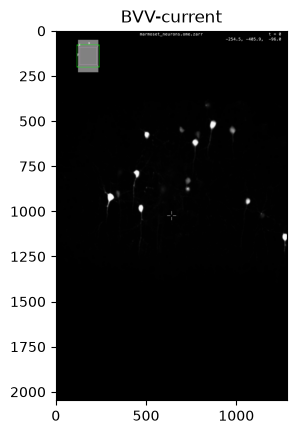

In [25]:
def apply_slab():
    # Restrict rendering to a 20 unit-thick slab centered on the soma
    stream_bvv.setSlab(soma.getZ(), 20.0)

if VIEWER == 'bvv' and STREAM_BVV and stream_bvv is not None:
    time.sleep(3)  # let the viewer open
    pysnt.run_on_edt(apply_slab)
    time.sleep(5)  # remote chunks take a while to arrive
    _ = pysnt.display(stream_bvv.snapshot())
    # stream_bvv.clearSlab() restores the full depth range

## Sharing Data with SNT Links

An *SNT link* is a `fiji://snt/open?...` URL that opens SNT (with the requested data) when clicked on a machine with SNT installed. Links accept a dataset (`image`), reconstructions (`tracings`) and a location to fly to (`view=x,y,z`, in calibrated coordinates). Streamed formats (`.zarr`, `.n5`, `s3://`, ...) open in SNT Stream by default. The helper below assembles them (SNT's *Create SNT Link* script does the same interactively).

In [26]:
def snt_link(image, tracings=None, view=None, viewer='bvv', tracer=True):
    """Assembles a fiji://snt/ link. Local paths must be absolute file: URIs"""
    params = {'image': quote(image, safe='')}
    if tracings:
        params['tracings'] = quote(tracings, safe='')
    if viewer == 'bdv':
        params['viewer'] = 'bdv'
    if not tracer:
        params['tracer'] = 'false'
    if view:
        params['view'] = ','.join(f'{c:.3f}' for c in view)  # commas are legal in values
    return 'fiji://snt/open?' + '&'.join(f'{k}={v}' for k, v in params.items())

# The whole remote volume + the provided tracings, flying to the soma we cropped
remote_link = snt_link(ZARR_URL, TRACINGS, view=(somas.iloc[0].X, somas.iloc[0].Y, somas.iloc[0].Z))
print(remote_link)

from IPython.display import Markdown
Markdown(f'[Open the full dataset in SNT Stream]({remote_link})')

fiji://snt/open?image=https%3A%2F%2Fome-zarr-scivis.s3.us-east-1.amazonaws.com%2Fv0.5%2F96x2%2Fmarmoset_neurons.ome.zarr&tracings=https%3A%2F%2Fraw.githubusercontent.com%2Fmorphonets%2Fmisc%2F3ffb1bee97666634faf12c060650a6052a30fc26%2Fdataset-demos%2Fmarmoset_neurons%2Fautotracings.traces&view=-134.343,-38.685,-96.255


[Open the full dataset in SNT Stream](fiji://snt/open?image=https%3A%2F%2Fome-zarr-scivis.s3.us-east-1.amazonaws.com%2Fv0.5%2F96x2%2Fmarmoset_neurons.ome.zarr&tracings=https%3A%2F%2Fraw.githubusercontent.com%2Fmorphonets%2Fmisc%2F3ffb1bee97666634faf12c060650a6052a30fc26%2Fdataset-demos%2Fmarmoset_neurons%2Fautotracings.traces&view=-134.343,-38.685,-96.255)

Links can only reference URLs or absolute local paths, so an in-memory crop cannot be linked directly. To share it, write the crop and its reconstruction to a temporary folder first and link to those files. `ImgUtils.saveAsOmeZarr()` writes a multiscale OME-Zarr, and the result is a link that only works on the machine that holds the files.

In [27]:
from pysnt.util import ImgUtils

tmp = Path(tempfile.mkdtemp(prefix='t09_'))

ImgUtils.saveAsOmeZarr(crop, tmp / 'crop.ome.zarr')  # pathlib.Path converts to java.io.File
tree.save(str(tmp / 'gwdt.traces'))

local_link = snt_link((tmp / 'crop.ome.zarr').as_uri(), (tmp / 'gwdt.traces').as_uri())
print(local_link)
Markdown(f'[Open the materialized crop in SNT]({local_link})')

fiji://snt/open?image=file%3A%2F%2F%2Fvar%2Ffolders%2Fgj%2Ffvy40kw16ld1gv1l58zjczzm0000gp%2FT%2Ft09_z8o90ww2%2Fcrop.ome.zarr&tracings=file%3A%2F%2F%2Fvar%2Ffolders%2Fgj%2Ffvy40kw16ld1gv1l58zjczzm0000gp%2FT%2Ft09_z8o90ww2%2Fgwdt.traces


[Open the materialized crop in SNT](fiji://snt/open?image=file%3A%2F%2F%2Fvar%2Ffolders%2Fgj%2Ffvy40kw16ld1gv1l58zjczzm0000gp%2FT%2Ft09_z8o90ww2%2Fcrop.ome.zarr&tracings=file%3A%2F%2F%2Fvar%2Ffolders%2Fgj%2Ffvy40kw16ld1gv1l58zjczzm0000gp%2FT%2Ft09_z8o90ww2%2Fgwdt.traces)

In [18]:
# Clean up resources
#pysnt.dispose()

## Summary

- `BigDataUtils.describe()` and `openChannel()` inspect and lazily open OME-Zarr (and N5, BDV-XML, IMS) data, local or remote, at any pyramid level, with consistent calibration. No Python-side zarr dependency is needed
- `NodeCollector` crops regions around locations of interest, and `ImgUtils.crop()` materializes the padded bounding box of a reconstruction, from lazy data
- GWDT tracing runs on materialized regions, with a backend chosen to fit memory, and can be compared with an existing tracing
- BVV (3D, GPU) and BDV (2D, CPU-only, lighter on slow connections) render the region and its reconstruction through the same API, `snapshot()` captures the scene, and `pysnt.run_on_edt()` makes this safe on macOS
- In BVV, `setSlab()` restricts rendering (and tile loading) to a slab, for responsive browsing of the whole remote volume
- SNT links reopen remote data (or locally saved crops) in SNT Stream

## Follow-up Questions

1. How does the reconstruction change if you trace the same region from a coarser level? When is the savings in transfer and memory worth the loss of detail?

2. The dataset has several channels. How would you materialize the same region from every channel (see the *Materialize Multichannel Region* script), and trace on a different channel than the one displayed?

3. For regions too large for RAM, what are the alternatives to full materialization (hint: tiled processing, and the disk-backed GWDT backend)?

## Data Sources and References

The marmoset neuron OME-Zarr volume is the demo dataset of SNT's *Big Data > SNT Stream* command. It is streamed from the public [OME-Zarr Open SciVis Datasets](https://github.com/InsightSoftwareConsortium/OMEZarrOpenSciVisDatasets) collection (`marmoset_neurons`), courtesy of Frederick Federer (Moran Eye Institute, University of Utah). The collection is distributed under CC-BY-4.0 unless otherwise specified (see the [AWS Open Data registry](https://registry.opendata.aws/ome-zarr-open-scivis/)). Please acknowledge the data source if you use it in your own work.

The soma detections and automated tracings are hosted in the [morphonets/misc](https://github.com/morphonets/misc/tree/master/dataset-demos/marmoset_neurons) repository.

For the OME-Zarr format specification, see:

- Moore J, Allan C, Beber S, et al. OME-NGFF: a next-generation file format for expanding bioimaging data-access strategies. Nat Methods. 2021;18(12):1496-1498. doi:[10.1038/s41592-021-01326-w](https://doi.org/10.1038/s41592-021-01326-w)

See [SNT citation](https://imagej.net/plugins/snt/faq#how-do-i-cite-snt) for details on how to properly cite SNT.

In [28]:
# Environment this notebook was last run with
import datetime, platform, re
from scyjava import jimport

snt_v = re.sub(r"(-SNAPSHOT-[0-9a-f]{7})[0-9a-f]+", r"\1", str(pysnt.snt_version()))
java_v = jimport("java.lang.System").getProperty("java.version")
print(f"Last run: {datetime.date.today():%Y-%m-%d}")
print(f"PySNT {pysnt.version()} | SNT {snt_v}")
print(f"Python {platform.python_version()} | Java {java_v} | {platform.system()} {platform.machine()}")

Last run: 2026-11-04
PySNT 5.0.0.dev0 | SNT 5.0.24-SNAPSHOT-95795a5
Python 3.12.16 | Java 21.0.10 | Darwin arm64
